In [58]:
# packages
import os
import numpy as np
import pandas as pd
import seaborn as sns
import pickle   
from matplotlib import pyplot as plt
import statsmodels.formula.api as smf
from scipy.special import logit
from scipy.stats import zscore
from scipy.stats import pearsonr

# what data set are we analysing
dataset = 'patient'

# paths
raw_path = '~/code/ast_human/data/raw/' + dataset + '/'
clean_path = '~/code/ast_human/data/clean/' + dataset + '/'
datalist_path = '~/code/ast_human/data/datalists/' + dataset + '/'

# make plotting dir
p = os.path.expanduser('~/code/ast_human/figures/') + dataset
os.makedirs(p, exist_ok=True)

# read data
data = pd.read_csv(clean_path + 'clean_data.csv')

In [80]:
palette = {
    'human': '#2b2b2f',
    'GH': '#745B95',
    'GH (hM4Di)':'#D68AFF',
    'ISO': '#8A8C96',
    'ISO (hM3Dq)': '#B7BAC5',
    'mouse': '#993bff',

    # Charcoals & greys
    'charcoal': '#2b2b2f',
    'dark_charcoal': '#1c1c1f',
    'patient': '#3d3d44',
    'slate': '#555763',
    'cool_grey': '#727480',
    'silver': '#a6a8b3',
    'light_grey': '#d2d4dc',

    # Accents
    'plotting_1': '#00c2ff',
    'plotting_2': '#ddbdff',
}

In [81]:
# lets buil the trajectories and shift cost plots

def plot_trajectories(df, stage = 'stage', n_errors = 'n_errors_stage', condition = None):

    '''
    plots errors/n_trials over blocks
    df = dataframe with errors per stage for each subject, will plot all stages you include
    stage = column name for stage
    n_errors = column name for errors
    agent = where did this data come from? human/simulation/animal?
    condition = column name for group or condition you want to split by
    '''
    
    sns.set_style("ticks")      # cleaner than whitegrid
    sns.set_context("paper", font_scale=1.3)

    # get stage names
    stages = df[stage].unique()

    plt.figure(figsize=(4,4))

    if condition == None:
        ax = sns.pointplot(df,
                        x = stage,
                        y = n_errors,
                        errorbar='se',
                        order=stages,
                        color=palette['charcoal'],
                        linewidth=4)
        plt.ylim(0)
    else:
        ax = sns.pointplot(df,
                        x = stage,
                        y = n_errors,
                        errorbar='se',
                        order=stages,
                        hue='condition',
                        palette=palette,
                        linewidth=4)
        ax.get_legend().remove()
        plt.ylim(0,14)

    
    sns.despine(ax=ax)
    plt.tight_layout()
    plt.ylabel('Number of Errors')
    plt.xlabel('')
    #plt.title(string.capwords(agent))
    plt.tight_layout()

    # save figure
    #if groups_used:
    #    plt.savefig('joint/plots/' + agent + '/trial_trajectory_' + "_".join(groups_used) +'.svg',format='svg')
    #else: 
    #    plt.savefig('joint/plots/' + agent + '/trial_trajectory.svg',format='svg')
    #return ax

In [86]:
def plot_costs(df, costs = 'shift_cost', condition = 'condition'):
    '''
    plots shift cost by group
    costs = name of shift cost column
    condition = name of condition column, set to None if using all data 
    '''
    
    sns.set_style("ticks")      # cleaner than whitegrid
    sns.set_context("paper", font_scale=1.3)

    conditions = df[condition].unique()
    plt.figure(figsize=(len(conditions) + 0.5,4))

    ax = sns.barplot(df,
                    x = condition,
                    y = costs,
                    errorbar='se',
                    hue='condition',
                    palette=palette,
                    linewidth=4)
    
    sns.despine(ax=ax)
    plt.tight_layout()
    plt.ylabel('Number of Errors')
    plt.xlabel('')
    plt.xticks(rotation=45)
    #plt.title(string.capwords(agent))
    plt.tight_layout()


    #if groups_used[0] == 'human':
    #    plt.savefig('joint/plots/human/shift_cost_' + "_".join(groups_used) +'.svg',format='svg')
    #else: 
    #    plt.savefig('joint/plots/mouse/shift_cost_'+ "_".join(groups_used) +'..svg',format='svg')
    #return ax


In [83]:
# calculate trajectories 
traj = data.groupby(['Participant Public ID', 'stage'])['n_errors_stage'].max()
traj = traj.reset_index()
traj['stage'] = traj['stage'].replace({
    0.0: 'SD',
    1.0: 'CD',
    2.0: 'IDS1',
    3.0: 'IDS2',
    4.0: 'IDS3',
    5.0: 'IDS4',
    6.0: 'EDS',
    7.0: 'EDSR'
})

# calculate shift costs
costs_df = traj[traj['stage'].isin(['IDS4','EDS'])]
costs_df = costs_df.pivot(index='Participant Public ID',columns='stage',values='n_errors_stage').reset_index()
costs_df['shift_cost'] = costs_df['EDS'] - costs_df['IDS4']
costs_df = costs_df.dropna()
costs_df['condition'] = 'patient'

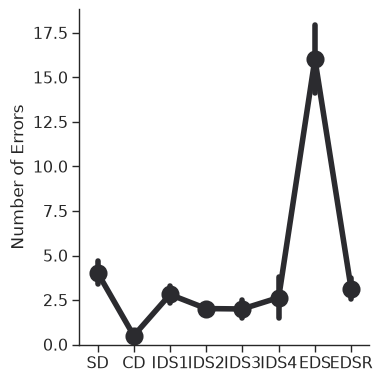

In [84]:
plot_trajectories(traj)

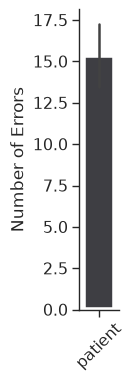

In [87]:
plot_costs(df=costs_df, costs='shift_cost', condition='condition')

In [26]:
def get_p_switch_after_correct(df, n_choices=5):
    results = []
    ids_stages = [s for s in df['stage'].unique() if 'IDS' in str(s)]
    ids_stages = [3,4,5,6,8,9,10,11]
    
    for pid, pdata in df.groupby('Participant Public ID'):
        for stage, sdata in pdata[pdata['stage'].isin(ids_stages)].groupby('stage'):
            sdata = sdata.reset_index(drop=True)
            
            correct_idx = sdata[sdata['reward'] == 1].index
            if len(correct_idx) == 0:
                continue
            first_correct = correct_idx[0]
            
            # Trials immediately after first correct
            window = sdata.iloc[first_correct + 1 : first_correct + 1 + n_choices]
            if len(window) == 0:
                continue
            
            # No reward = switched away from correct dimension
            p_switch = (window['reward'] == 0).mean()
            results.append({
                'Participant Public ID': pid,
                'stage': stage,
                'p_switch': p_switch,
                'n_trials': len(window)
            })
    
    results_df = pd.DataFrame(results)
    participant_means = results_df.groupby('Participant Public ID')['p_switch'].mean().reset_index()
    return participant_means, results_df

In [29]:
means, results = get_p_switch_after_correct(data, n_choices=3)

(array([ 4., 19., 22.,  1.,  1.,  0.,  0.,  0.,  0.,  1.]),
 array([0.08333333, 0.15277778, 0.22222222, 0.29166667, 0.36111111,
        0.43055556, 0.5       , 0.56944444, 0.63888889, 0.70833333,
        0.77777778]),
 <BarContainer object of 10 artists>)

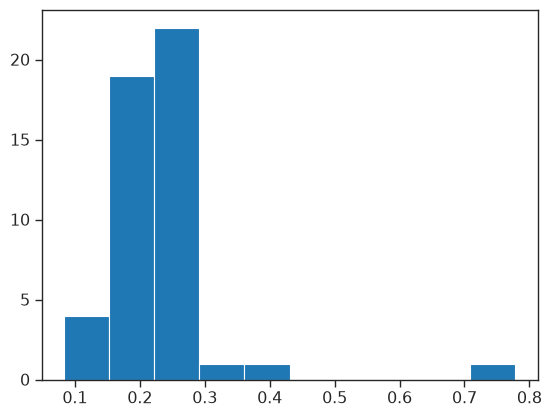

In [30]:
plt.hist(means['p_switch'])

In [11]:
# MH - behaviour correlations

# questionnaire list
qaires = ['CTQ', 'GAD', 'IUS', 'OCI_R', 'PHQ', 'SMSS', 'AES']
factors = ['F1', 'F2', 'F3', 'F4']
subscale = ['e_abuse', 'p_abuse', 's_abuse', 'e_neglect', 'p_neglect']

# read questionnaires and bind
ctq = pd.read_csv(clean_path + 'online_study/ctq.csv', index_col=0)
ctq.rename(columns={'Response': 'CTQ'}, inplace=True)
gad = pd.read_csv(clean_path + 'online_study/gad.csv', index_col=0)
gad.rename(columns={'Response': 'GAD'}, inplace=True)
ius = pd.read_csv(clean_path + 'online_study/ius.csv', index_col=0)
ius.rename(columns={'Response': 'IUS'}, inplace=True)
oci_r = pd.read_csv(clean_path + 'online_study/oci_r.csv', index_col=0)
oci_r.rename(columns={'Response': 'OCI_R'}, inplace=True)
phq = pd.read_csv(clean_path + 'online_study/phq.csv', index_col=0)
phq.rename(columns={'Response': 'PHQ'}, inplace=True)
SMSS = pd.read_csv(clean_path + 'online_study/schiz.csv', index_col=0)
SMSS.rename(columns={'Response': 'SMSS'}, inplace=True)
aes = pd.read_csv(clean_path + 'online_study/aes.csv', index_col=0)
aes.rename(columns={'Response': 'AES'}, inplace=True)
init = main[['Participant Public ID', 'Manipulation: initial_dimension']].drop_duplicates()
init = init.rename(columns={"Manipulation: initial_dimension": "init"})

# merge with data
tmp_df = tmp_shifts.merge(ctq, on='Participant Public ID') \
                  .merge(gad, on='Participant Public ID') \
                  .merge(ius, on='Participant Public ID') \
                  .merge(oci_r, on='Participant Public ID') \
                  .merge(phq, on='Participant Public ID') \
                  .merge(SMSS, on='Participant Public ID') \
                  .merge(aes, on='Participant Public ID') \
                  .merge(init, on='Participant Public ID') \
                  .merge(demographics, on='Participant Public ID') \
                  .merge(pca, on='Participant Public ID')

# remove random high ctq ppt
tmp_df = tmp_df[~(tmp_df['CTQ'] > 150)]
#tmp_df['passed'] = tmp_df['Participant Public ID'].isin(x).astype(int)
# z score variables
#tmp_df['costs'] = zscore(tmp_df['costs'])
tmp_df['Age'] = zscore(tmp_df['Age'])
tmp_df = tmp_df[tmp_df['Sex'].isin(['Male','Female'])]

# loop over all qs
for q in qaires:

    # run simple correlation 
    print(pearsonr(tmp_df["costs"],tmp_df[q]))

    # z score current q 
    #tmp_df[q] = zscore(tmp_df[q])

    # run model and print output
    formula = 'costs ~ ' + q + ' + init + Sex + Age'
    model = smf.ols(formula, data=tmp_df).fit()
    print(model.summary())


PearsonRResult(statistic=np.float64(-0.009684062731641553), pvalue=np.float64(0.7336592950451954))
                            OLS Regression Results                            
Dep. Variable:                  costs   R-squared:                       0.044
Model:                            OLS   Adj. R-squared:                  0.041
Method:                 Least Squares   F-statistic:                     14.07
Date:                Fri, 04 Sep 2026   Prob (F-statistic):           3.10e-11
Time:                        13:14:24   Log-Likelihood:                -4761.7
No. Observations:                1237   AIC:                             9533.
Df Residuals:                    1232   BIC:                             9559.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------

In [15]:
tmp_df[tmp_df['e_abuse']>=16]

,costs,Participant Public ID,task,CTQ,e_abuse,p_abuse,s_abuse,e_neglect,p_neglect,GAD,...,SMSS,AES,init,Age,Sex,Unnamed: 0,F1,F2,F3,F4
2,1.0,544e94c4fdf99b50bd30726c,main,83,24,13,5,25,16,15,...,27,40,0.0,1.023675,Male,2,1.698800,1.449654,3.056211,-0.385803
18,4.0,56764223193963000551db43,main,90,24,15,7,25,19,9,...,25,46,1.0,-0.700267,Female,22,1.329458,1.631721,3.170827,0.160107
19,11.0,56771c1019396300055222d0,main,85,22,15,17,20,11,18,...,31,52,1.0,-0.289804,Female,23,1.963850,2.191177,2.527678,3.703165
26,15.0,56b8ad1be1d0a2000c154093,main,73,20,9,8,21,15,2,...,19,48,0.0,1.762508,Female,32,0.139368,1.019618,1.998606,0.657645
27,4.0,56cefc4cb009e1000aa73684,main,72,23,21,5,16,7,0,...,2,21,1.0,-0.618174,Female,33,-1.133788,-1.501905,2.001235,-0.113595
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1196,5.0,6978d0c62defec8ac81f940b,main,61,18,9,5,15,14,16,...,20,30,0.0,-0.700267,Female,1270,1.319538,0.546502,1.572566,-0.389968
1224,22.0,6983caa6076463e2778f6456,main,56,23,6,5,15,7,8,...,25,36,1.0,-1.767469,Female,1299,1.060318,0.091016,1.331284,-0.315795
1225,2.0,69857f94a888206382aaf459,main,85,25,20,5,23,12,16,...,31,36,1.0,-1.110729,Female,1300,1.682152,0.896208,3.314394,-0.333963
1226,1.0,698a016812567347276f36ed,main,91,18,9,24,21,19,11,...,23,40,0.0,-1.931654,Female,1301,1.384088,0.791443,2.362279,5.401580


PearsonRResult(statistic=np.float64(0.06408789757877947), pvalue=np.float64(0.02419146236214657))
                            OLS Regression Results                            
Dep. Variable:                  costs   R-squared:                       0.050
Model:                            OLS   Adj. R-squared:                  0.047
Method:                 Least Squares   F-statistic:                     16.36
Date:                Mon, 03 Aug 2026   Prob (F-statistic):           4.55e-13
Time:                        12:32:56   Log-Likelihood:                -4757.4
No. Observations:                1237   AIC:                             9525.
Df Residuals:                    1232   BIC:                             9550.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------

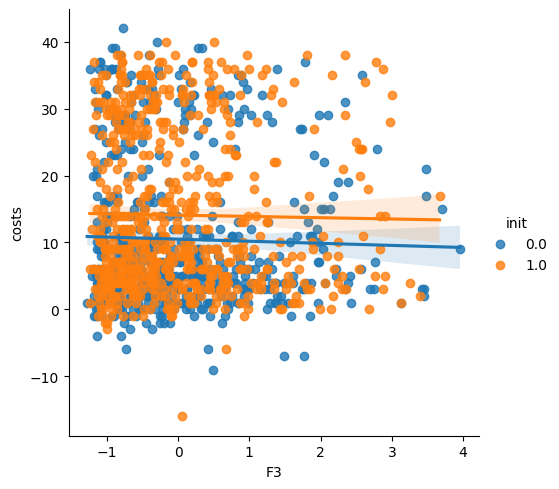

In [11]:
# loop over all factors
for q in factors:

    # run simple correlation 
    print(pearsonr(tmp_df["costs"],tmp_df[q]))

    # z score current q 
    tmp_df[q] = zscore(tmp_df[q])

    # run model and print output
    formula = 'costs ~ ' + q + ' + init + Sex + Age'
    model = smf.ols(formula, data=tmp_df).fit()
    print(model.summary())

# plot correlations
sns.lmplot(
    data=tmp_df,
    x='F3',
    y='costs',
    hue='init',  # 0 vs 1
    ci=95
)

plt.show()

PearsonRResult(statistic=np.float64(-0.03857510973229634), pvalue=np.float64(0.1751441541684767))
                            OLS Regression Results                            
Dep. Variable:                  costs   R-squared:                       0.045
Model:                            OLS   Adj. R-squared:                  0.042
Method:                 Least Squares   F-statistic:                     14.51
Date:                Mon, 03 Aug 2026   Prob (F-statistic):           1.38e-11
Time:                        12:33:00   Log-Likelihood:                -4760.9
No. Observations:                1237   AIC:                             9532.
Df Residuals:                    1232   BIC:                             9557.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------

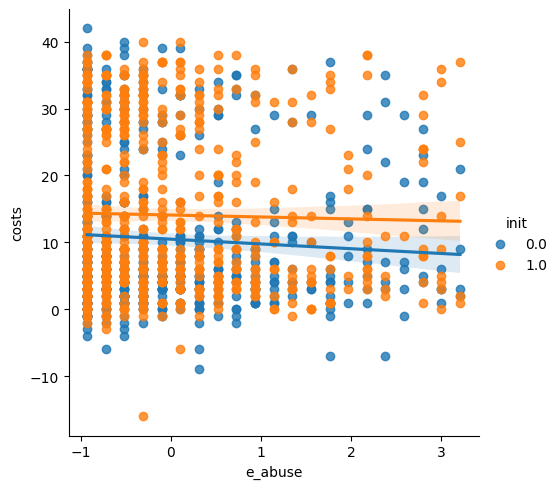

In [12]:
# loop over all subscale
for q in subscale:

    # run simple correlation 
    print(pearsonr(tmp_df["costs"],tmp_df[q]))

    # z score current q 
    tmp_df[q] = zscore(tmp_df[q])

    # run model and print output
    formula = 'costs ~ ' + q + ' + Sex + init + Sex + Age'
    model = smf.ols(formula, data=tmp_df).fit()
    print(model.summary())

# plot correlations
sns.lmplot(
    data=tmp_df,
    x='e_abuse',
    y='costs',
    hue='init',  # 0 vs 1
    ci=95
)

plt.show()

In [13]:
# bind parameters to qaire and behaviour data
tmp_df = pd.merge(tmp_df, params, on='Participant Public ID')
params_list = ['alpha', 't0', 'eps']

# untransform parameters
tmp_df['alpha'] = zscore(logit(tmp_df['alpha']))
#tmp_df['beta'] = zscore(np.log(tmp_df['beta']))
tmp_df['t0'] = zscore(np.log(tmp_df['t0']))
tmp_df['eps'] = zscore(logit(tmp_df['eps']))

# check correlation between params and behaviour
for param in params_list:
    print(pearsonr(tmp_df["costs"],tmp_df[param]))

PearsonRResult(statistic=np.float64(-0.5823505491410327), pvalue=np.float64(3.2428627604816537e-113))
PearsonRResult(statistic=np.float64(0.7105335086803798), pvalue=np.float64(9.99524303433862e-191))
PearsonRResult(statistic=np.float64(0.41825281482758353), pvalue=np.float64(1.4596384747662014e-53))


In [14]:
# # correlations parameters and MH
param = 'alpha'

# loop over qaires
for q in qaires:

    # simple correlation
    print(pearsonr(tmp_df[q],tmp_df[param]))

    # regression
    formula = q + ' ~ ' + param + ' * init + Age + Sex'
    model = smf.ols(formula, data=tmp_df).fit()
    print(model.summary())


PearsonRResult(statistic=np.float64(0.0012758026380675109), pvalue=np.float64(0.9642460625594865))
                            OLS Regression Results                            
Dep. Variable:                    CTQ   R-squared:                       0.011
Model:                            OLS   Adj. R-squared:                  0.007
Method:                 Least Squares   F-statistic:                     2.703
Date:                Mon, 03 Aug 2026   Prob (F-statistic):             0.0194
Time:                        12:33:12   Log-Likelihood:                -1748.5
No. Observations:                1237   AIC:                             3509.
Df Residuals:                    1231   BIC:                             3540.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------

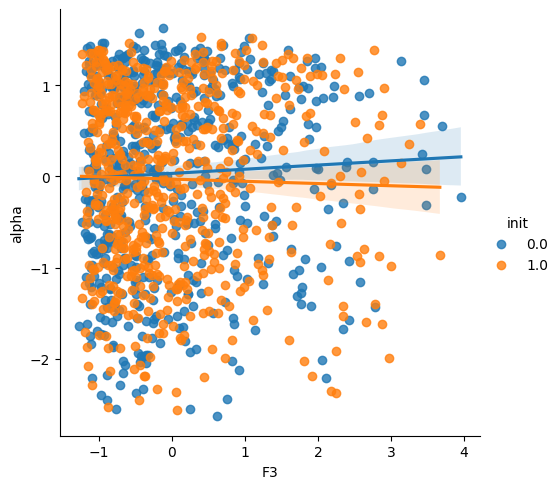

In [15]:
# plot correlations
sns.lmplot(
    data=tmp_df,
    x='F3',
    y='alpha',
    hue='init',  # 0 vs 1
    ci=95
)

plt.show()
#plt.savefig('plots/old_scatter.svg', format='svg')

In [16]:
# correlations with other task stages
tmp = tmp_errors[tmp_errors['stage'].isin(['IDS1'])]
totals = tmp.groupby('Participant Public ID')['n_errors'].sum().reset_index()
totals = totals.merge(tmp_df, on='Participant Public ID')
totals['n_errors'] = zscore(totals['n_errors'])

for q in factors:
    print(pearsonr(totals['n_errors'],totals[q]))
    formula = 'n_errors ~ ' + q + ' + init + Age + Sex'
    model = smf.ols(formula, data=totals).fit()
    print(model.summary())


PearsonRResult(statistic=np.float64(0.09121736578310655), pvalue=np.float64(0.001319699980475832))
                            OLS Regression Results                            
Dep. Variable:               n_errors   R-squared:                       0.020
Model:                            OLS   Adj. R-squared:                  0.017
Method:                 Least Squares   F-statistic:                     6.346
Date:                Mon, 03 Aug 2026   Prob (F-statistic):           4.70e-05
Time:                        12:33:16   Log-Likelihood:                -1742.6
No. Observations:                1237   AIC:                             3495.
Df Residuals:                    1232   BIC:                             3521.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------

In [18]:
# correlations with IDS1-4 slope?

tmp = tmp_errors[tmp_errors['stage'].isin(['IDS1','IDS2','IDS3','IDS4'])]

# pivot for difference
tmp = tmp.pivot(index='Participant Public ID', values='n_errors', columns='stage')
tmp['diff'] = tmp['IDS1'] - tmp['IDS4']
tmp['sum'] = tmp['IDS1'] + tmp['IDS2'] + tmp['IDS3'] + tmp['IDS4']
tmp = tmp.merge(tmp_df, on='Participant Public ID')
tmp.dropna(inplace=True)
tmp['diff'] = zscore(tmp['diff'])
for q in qaires:
    print(pearsonr(tmp['diff'],tmp[q]))
    formula = 'costs ~ t0 + init + Age + Sex'
    model = smf.ols(formula, data=tmp).fit()
    print(model.summary())


PearsonRResult(statistic=np.float64(0.023887976130396338), pvalue=np.float64(0.4012254418910248))
                            OLS Regression Results                            
Dep. Variable:                  costs   R-squared:                       0.508
Model:                            OLS   Adj. R-squared:                  0.507
Method:                 Least Squares   F-statistic:                     318.5
Date:                Mon, 03 Aug 2026   Prob (F-statistic):          3.35e-188
Time:                        12:33:24   Log-Likelihood:                -4350.2
No. Observations:                1237   AIC:                             8710.
Df Residuals:                    1232   BIC:                             8736.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------

PearsonRResult(statistic=np.float64(0.09899567080944263), pvalue=np.float64(0.0004887896708820105))
                            OLS Regression Results                            
Dep. Variable:                  costs   R-squared:                       0.054
Model:                            OLS   Adj. R-squared:                  0.050
Method:                 Least Squares   F-statistic:                     14.11
Date:                Mon, 03 Aug 2026   Prob (F-statistic):           1.93e-13
Time:                        12:33:26   Log-Likelihood:                -4754.9
No. Observations:                1237   AIC:                             9522.
Df Residuals:                    1231   BIC:                             9553.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
------------------------------

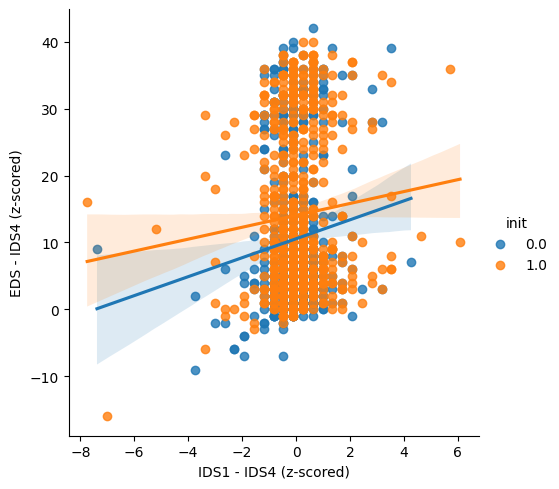

In [19]:
# plot correlations

print(pearsonr(x=tmp['diff'],y=tmp['costs']))
formula = 'costs ~  diff * init + Age + Sex'
model = smf.ols(formula, data=tmp).fit()
print(model.summary())

sns.lmplot(
    data=tmp,
    x='diff',
    y='costs',
    hue='init',  # 0 vs 1
    ci=95
)
plt.xlabel('IDS1 - IDS4 (z-scored)')
plt.ylabel('EDS - IDS4 (z-scored)')
plt.savefig('plots/cost_diff_scatter.png', format='png')
plt.show()

In [20]:
# lets look at some extra covariates

# loop over all qs
for q in subscale:

    # run simple correlation 
    print(pearsonr(tmp_df["costs"],tmp_df[q]))

    # run model and print output
    formula = 'costs ~ ' + q + ' + init + Sex + Age'
    model = smf.ols(formula, data=tmp_df).fit()
    print(model.summary())

PearsonRResult(statistic=np.float64(-0.03857510973229634), pvalue=np.float64(0.1751441541684767))
                            OLS Regression Results                            
Dep. Variable:                  costs   R-squared:                       0.045
Model:                            OLS   Adj. R-squared:                  0.042
Method:                 Least Squares   F-statistic:                     14.51
Date:                Mon, 03 Aug 2026   Prob (F-statistic):           1.38e-11
Time:                        12:33:29   Log-Likelihood:                -4760.9
No. Observations:                1237   AIC:                             9532.
Df Residuals:                    1232   BIC:                             9557.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------

In [24]:
# big regression
from statsmodels.stats.outliers_influence import variance_inflation_factor

# run model and print output
tmp['e'] = (tmp['e_abuse'] + tmp['e_neglect'])/2
tmp['p'] = (tmp['p_abuse'] + tmp['p_neglect'])/2
tmp_2 = tmp.copy()
#tmp_2 = tmp_2[(tmp_2['e_abuse'] < 3) & (tmp_2['e_abuse'] > -2)]

# formula
#formula = 'eps ~ CTQ + PHQ + IUS + OCI_R + GAD + SMSS + AES + Sex + Age + init'
#formula = 'eps ~ F1 + F2 + F3 + F4 + Sex + init + Age'
formula = "eps ~ e_abuse + e_neglect + s_abuse + p_abuse + p_neglect + F1 + F2 + Sex + Age + init"

model = smf.ols(formula, data=tmp).fit()
table = model.summary2().tables[1]

pub_table = table[['Coef.', 'Std.Err.', 'P>|t|']].copy()

pub_table.columns = ['B', 'SE', 'p']

pub_table['B'] = pub_table['B'].round(2)
pub_table['SE'] = pub_table['SE'].round(2)
pub_table['p'] = pub_table['p'].round(3)

print(pub_table)
print(tmp[['e_abuse', 'e_neglect', 'p_abuse', 'p_neglect', 's_abuse']].corr())
print(tmp[['OCI_R', 'IUS', 'GAD']].corr())
#pub_table.to_csv('data/clean/online_study/factor_beta_regression_table.csv')

                B    SE      p
Intercept   -0.18  0.05  0.000
Sex[T.Male]  0.07  0.06  0.236
e_abuse     -0.03  0.05  0.623
e_neglect   -0.06  0.05  0.234
s_abuse      0.03  0.03  0.326
p_abuse     -0.00  0.04  0.993
p_neglect    0.01  0.04  0.761
F1           0.05  0.04  0.150
F2          -0.02  0.04  0.516
Age          0.10  0.03  0.001
init         0.29  0.06  0.000
            e_abuse  e_neglect   p_abuse  p_neglect   s_abuse
e_abuse    1.000000   0.758913  0.628935   0.602159  0.353438
e_neglect  0.758913   1.000000  0.522692   0.633978  0.280710
p_abuse    0.628935   0.522692  1.000000   0.467708  0.324438
p_neglect  0.602159   0.633978  0.467708   1.000000  0.274244
s_abuse    0.353438   0.280710  0.324438   0.274244  1.000000
          OCI_R       IUS       GAD
OCI_R  1.000000  0.622665  0.643253
IUS    0.622665  1.000000  0.593978
GAD    0.643253  0.593978  1.000000


In [35]:
import statsmodels.api as sm
# Select the predictors only
X = tmp[['e_abuse', 'p_abuse', 's_abuse', 'p_neglect', 'e_neglect',
         'F1', 'F2',
         'Sex', 'Age', 'init']].copy()
X['Sex'] = X['Sex'].map({'Male': 0, 'Female': 1})

# If there are missing values
X = X.dropna()

# Add intercept
X = sm.add_constant(X)

# Compute VIF
vif = pd.DataFrame({
    'Variable': X.columns,
    'VIF': [variance_inflation_factor(X.values, i)
            for i in range(X.shape[1])]
})

# Drop the intercept
vif = vif[vif['Variable'] != 'const']

print(vif.sort_values('VIF', ascending=False))

     Variable       VIF
1     e_abuse  3.381465
5   e_neglect  2.905924
4   p_neglect  1.826809
2     p_abuse  1.786910
6          F1  1.754214
7          F2  1.621192
3     s_abuse  1.195161
9         Age  1.089843
8         Sex  1.061857
10       init  1.005728


                 B     SE      p  p_FDR  Significant
Intercept   -0.173  0.046  0.000  0.001         True
Sex[T.Male] -0.161  0.056  0.004  0.008         True
e_abuse     -0.148  0.050  0.003  0.007         True
e_neglect    0.036  0.046  0.435  0.478        False
s_abuse      0.025  0.030  0.394  0.478        False
p_abuse      0.066  0.036  0.068  0.107        False
p_neglect    0.016  0.037  0.661  0.661        False
F1           0.106  0.036  0.003  0.007         True
F2          -0.058  0.034  0.091  0.125        False
Age          0.145  0.028  0.000  0.000         True
init         0.487  0.054  0.000  0.000         True


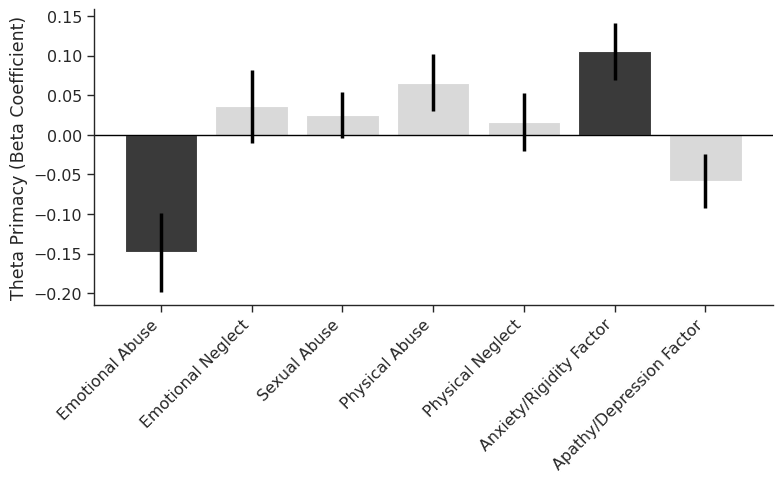

In [43]:
from statsmodels.stats.multitest import multipletests

table = model.summary2().tables[1]

pvals = table['P>|t|']

reject, p_fdr, _, _ = multipletests(pvals, method='fdr_bh')

table['p_FDR'] = p_fdr
table['significant_FDR'] = reject

results = pd.DataFrame({
    'B': table['Coef.'],
    'SE': table['Std.Err.'],
    'p': pvals,
    'p_FDR': p_fdr,
    'Significant': reject
})
print(results.round(3))

plot_results = results
plot_results = plot_results[~plot_results.index.isin(['Intercept', 'Sex[T.Male]', 'Age', 'init'])]
plot_results = plot_results.rename(index={'e_abuse': 'Emotional Abuse', 'e_neglect': 'Emotional Neglect', 'p_abuse': 'Physical Abuse',
                                          'p_neglect': 'Physical Neglect', 's_abuse': 'Sexual Abuse', 'F1': 'Anxiety/Rigidity Factor',
                                          'F2': 'Apathy/Depression Factor', })

import seaborn as sns
import matplotlib.pyplot as plt

df = plot_results.reset_index().rename(columns={"index": "Predictor"})

sns.set_style("ticks")      # cleaner than whitegrid
sns.set_context("paper", font_scale=1.3)

palette = {
    True: "#3a3a3a",    # charcoal
    False: "#d9d9d9"    # light grey
}

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=df,
    x="Predictor",
    y="B",
    hue="Significant",
    palette=palette,
    dodge=False,
    errorbar=None,
    legend=False
)

# Add thicker error bars with NO caps
ax.errorbar(
    x=range(len(df)),
    y=df["B"],
    yerr=df["SE"],
    fmt="none",
    ecolor="black",
    elinewidth=2.5,   # thickness
    capsize=0         # removes horizontal caps
)

# Horizontal reference line at zero
ax.axhline(0, color="black", linewidth=1)

# Remove top and right spines
sns.despine(ax=ax)

# Or equivalently:
# ax.spines["top"].set_visible(False)
# ax.spines["right"].set_visible(False)

plt.xticks(rotation=45, ha="right")
plt.ylabel("Theta Primacy (Beta Coefficient)")
plt.xlabel("")

plt.tight_layout()
plt.savefig("plots/t0_forest.svg", format='svg', dpi=300, bbox_inches="tight")
plt.show()

In [137]:
from statsmodels.stats.multitest import multipletests
import pandas as pd

table = model.summary2().tables[1].copy()

pvals = table['P>|t|']

reject, p_fdr, _, _ = multipletests(pvals, method='fdr_bh')

results = pd.DataFrame({
    'B': table['Coef.'],
    'SE': table['Std.Err.'],
    't': table['t'],
    'p': pvals,
    'p_FDR': p_fdr,
    'Significant_FDR': reject
})

# add variable names
results.index.name = 'Variable'

# sort by raw p-value (standard for FDR tables)
results = results.sort_values('p')

# optional: nicer rounding
results = results.round({
    'B': 3,
    'SE': 3,
    't': 3,
    'p': 4,
    'p_FDR': 4
})

print(results)

                  B     SE       t       p   p_FDR  Significant_FDR
Variable                                                           
Intercept    11.212  0.552  20.322  0.0000  0.0000             True
init          3.572  0.645   5.536  0.0000  0.0000             True
Age           1.535  0.335   4.577  0.0000  0.0000             True
F1            1.782  0.426   4.182  0.0000  0.0001             True
e_abuse      -1.425  0.592  -2.409  0.0162  0.0307             True
Sex[T.Male]  -1.598  0.667  -2.395  0.0168  0.0307             True
F2           -0.634  0.410  -1.549  0.1216  0.1912            False
p_neglect     0.299  0.435   0.687  0.4922  0.6723            False
s_abuse       0.210  0.352   0.598  0.5501  0.6723            False
p_abuse       0.211  0.430   0.491  0.6238  0.6862            False
e_neglect     0.044  0.548   0.080  0.9365  0.9365            False


In [ ]:
from statsmodels.stats.multitest import multipletests

table = model.summary2().tables[1]

# Variables you want to correct over
hypothesis_vars = [
    'e_abuse', 'e_neglect', 'p_abuse', 'p_neglect', 's_abuse',
    'F1', 'F2'
]

pvals = table.loc[hypothesis_vars, 'P>|t|']

# Benjamini-Hochberg FDR
reject, p_fdr, _, _ = multipletests(
    pvals,
    alpha=0.05,
    method='fdr_bh'
)

results = pd.DataFrame({
    'B': table.loc[hypothesis_vars, 'Coef.'],
    'SE': table.loc[hypothesis_vars, 'Std.Err.'],
    'p': pvals,
    'p_FDR': p_fdr,
    'Significant': reject
})

print(results.round(3))

               B     SE      p  p_FDR  Significant
e_abuse   -1.425  0.592  0.016  0.057        False
e_neglect  0.044  0.548  0.937  0.937        False
p_abuse    0.211  0.430  0.624  0.728        False
p_neglect  0.299  0.435  0.492  0.728        False
s_abuse    0.210  0.352  0.550  0.728        False
F1         1.782  0.426  0.000  0.000         True
F2        -0.634  0.410  0.122  0.284        False


In [ ]:
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

n_boot = 5000
boot_indirect = []

data = tmp.copy()

formula_m = "F1 ~ e_abuse + e_neglect + s_abuse + p_abuse + p_neglect + F2 + Sex + Age + init"
formula_y = "costs ~ e_abuse + F1 + e_neglect + s_abuse + p_abuse + p_neglect + F2 + Sex + Age + init"

for i in range(n_boot):
    sample = data.sample(n=len(data), replace=True)

    # mediator model (a path)
    m_model = smf.ols(formula_m, data=sample).fit()
    a = m_model.params["e_abuse"]

    # outcome model (b and c' paths)
    y_model = smf.ols(formula_y, data=sample).fit()
    b = y_model.params["F1"]

    indirect = a * b
    boot_indirect.append(indirect)

boot_indirect = np.array(boot_indirect)

# summary
ind_mean = np.mean(boot_indirect)
ci_low = np.percentile(boot_indirect, 2.5)
ci_high = np.percentile(boot_indirect, 97.5)

print("Indirect effect (a*b):", ind_mean)
print("95% CI:", (ci_low, ci_high))

Indirect effect (a*b): 0.48691474475614116
95% CI: (np.float64(0.22364884843598226), np.float64(0.8015726869780145))


In [113]:
# final fitted models on full data
m_model = smf.ols(formula_m, data=data).fit()
y_model = smf.ols(formula_y, data=data).fit()

a = m_model.params["e_abuse"]
b = y_model.params["F1"]
c_prime = y_model.params["e_abuse"]

indirect = a * b
total = c_prime + indirect

print("a (X→M):", a)
print("b (M→Y):", b)
print("direct c':", c_prime)
print("indirect a*b:", indirect)
print("total effect:", total)

a (X→M): 0.2734598112596397
b (M→Y): 1.781669015337539
direct c': -1.424799162131965
indirect a*b: 0.4872148726613515
total effect: -0.9375842894706135


In [122]:
from statsmodels.stats.multitest import multipletests

table = y_model.summary2().tables[1]

pvals = table['P>|t|']

reject, p_fdr, _, _ = multipletests(pvals, method='fdr_bh')

table['p_FDR'] = p_fdr
table['significant_FDR'] = reject
print(table)

                 Coef.  Std.Err.          t         P>|t|     [0.025  \
Intercept    11.212097  0.551709  20.322476  2.307508e-79  10.129698   
Sex[T.Male]  -1.597869  0.667079  -2.395321  1.675512e-02  -2.906612   
e_abuse      -1.424799  0.591544  -2.408612  1.616011e-02  -2.585349   
F1            1.781669  0.426065   4.181686  3.099361e-05   0.945772   
e_neglect     0.043669  0.548374   0.079634  9.365413e-01  -1.032185   
s_abuse       0.210227  0.351680   0.597780  5.500970e-01  -0.479734   
p_abuse       0.210937  0.430017   0.490531  6.238458e-01  -0.632714   
p_neglect     0.298690  0.434791   0.686972  4.922302e-01  -0.554328   
F2           -0.634448  0.409592  -1.548976  1.216455e-01  -1.438028   
Age           1.534985  0.335354   4.577203  5.191426e-06   0.877053   
init          3.571744  0.645232   5.535594  3.790472e-08   2.305862   

                0.975]         p_FDR  significant_FDR  
Intercept    12.294495  2.538259e-78             True  
Sex[T.Male]  -0.289125 

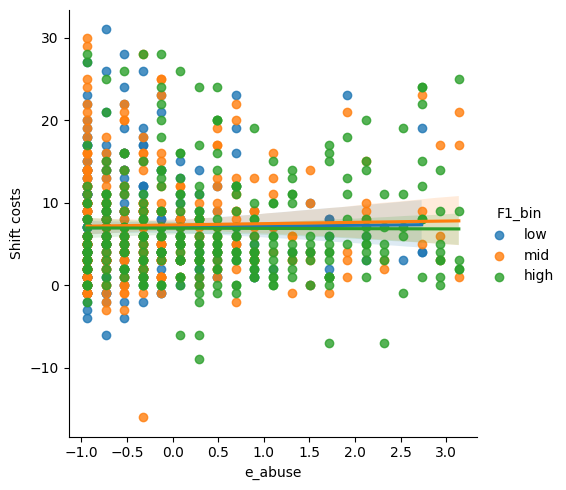

In [ ]:
import seaborn as sns
tmp_df["F1_bin"] = pd.qcut(tmp_df["F1"], 3, labels=["low", "mid", "high"])

ius_plot = sns.lmplot(
    x="e_abuse",
    y="costs",
    hue="F1_bin",
    data=tmp_df
)
plt.ylabel('Shift costs')
plt.savefig('plots/IUS_SC_scatter.svg',format='svg')

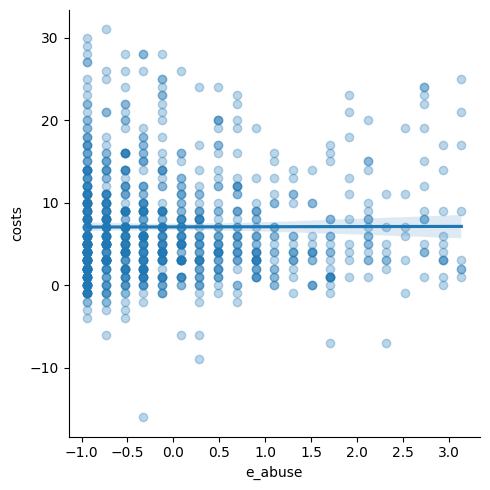

In [221]:
sns.lmplot(
    x="e_abuse",
    y="costs",
    data=tmp_df,
    scatter_kws={"alpha":0.3}
)

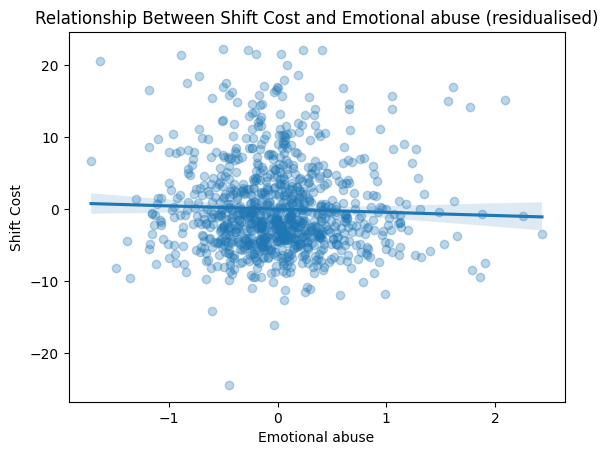

In [ ]:
import statsmodels.api as sm
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

controls = ["F1", "Age", "Sex", "init", 'e_neglect', 'p_abuse', 'p_neglect', 's_abuse']

# --- build design matrix ---
X_controls = pd.get_dummies(tmp_2[controls], drop_first=True)
X_controls = X_controls.astype(float)   # force numeric
X_controls = sm.add_constant(X_controls)

# --- residualize PC3 ---
model_pc3 = sm.OLS(tmp_2["e_abuse"].astype(float), X_controls).fit()
resid_pc3 = model_pc3.resid

# --- residualize costs ---
model_costs = sm.OLS(tmp_2["costs"].astype(float), X_controls).fit()
resid_costs = model_costs.resid

# --- plot ---
sns.regplot(
    x=resid_pc3,
    y=resid_costs,
    scatter_kws={"alpha": 0.3}
)

plt.xlabel("Emotional abuse")
plt.ylabel("Shift Cost")
plt.title("Relationship Between Shift Cost and Emotional abuse (residualised)")
plt.savefig('plots/e_abuse_partial_effect.svg',format='svg')
plt.show()

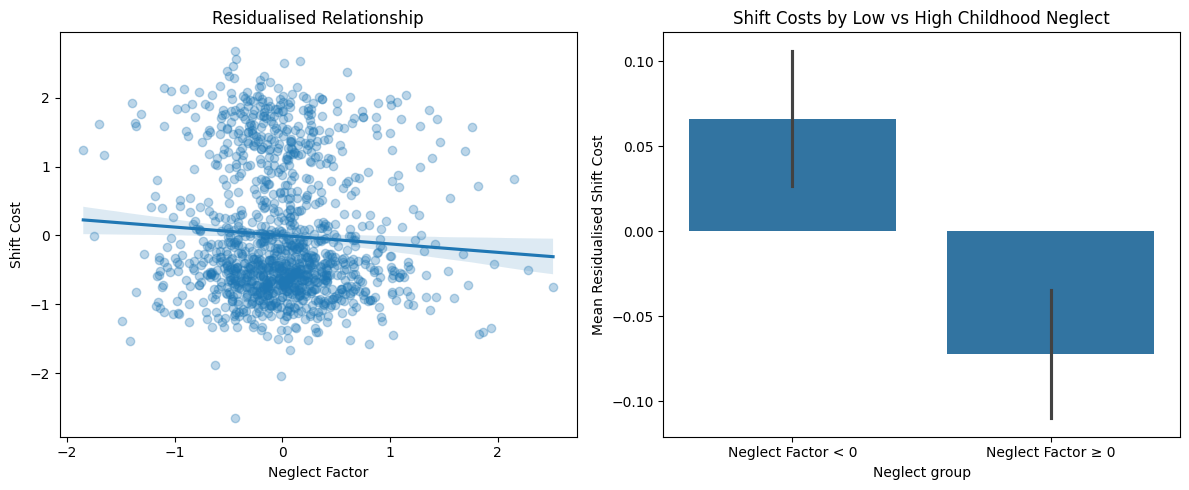

In [86]:
import statsmodels.api as sm
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

controls = ["F1", "Age", "Sex", "init", 'e_neglect', 'p_abuse', 'p_neglect', 's_abuse']

# --- build design matrix ---
X_controls = pd.get_dummies(tmp_df[controls], drop_first=True)
X_controls = X_controls.astype(float)
X_controls = sm.add_constant(X_controls)

# --- residualize PC3 ---
model_pc3 = sm.OLS(tmp_df["e_abuse"].astype(float), X_controls).fit()
resid_pc3 = model_pc3.resid

# --- residualize costs ---
model_costs = sm.OLS(tmp_df["costs"].astype(float), X_controls).fit()
resid_costs = model_costs.resid

# --- dataframe for plotting ---
plot_df = pd.DataFrame({
    "resid_pc3": resid_pc3,
    "resid_costs": resid_costs
})

# split PC3 above/below 0
plot_df["Neglect group"] = np.where(
    plot_df["resid_pc3"] >= 0,
    "Neglect Factor ≥ 0",
    "Neglect Factor < 0"
)

# --- figure with 2 panels ---
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# =========================
# Left: regression plot
# =========================
sns.regplot(
    data=plot_df,
    x="resid_pc3",
    y="resid_costs",
    scatter_kws={"alpha": 0.3},
    ax=axes[0]
)

axes[0].set_xlabel("Neglect Factor")
axes[0].set_ylabel("Shift Cost")
axes[0].set_title("Residualised Relationship")

# =========================
# Right: barplot
# =========================
sns.barplot(
    data=plot_df,
    x="Neglect group",
    y="resid_costs",
    errorbar="se",
    ax=axes[1]
)

axes[1].set_xlabel("Neglect group")
axes[1].set_ylabel("Mean Residualised Shift Cost")
axes[1].set_title("Shift Costs by Low vs High Childhood Neglect")

plt.tight_layout()

plt.savefig('plots/f3_partial_effect.svg', format='svg')
plt.show()

In [178]:
tmp_df['Sex'].unique()

array(['Male', 'Female', 'DATA_EXPIRED', 'Prefer not to say'],
      dtype=object)

In [ ]:
tmp_x = tmp_df[~tmp_df['Participant Public ID'].isin(x)]
tmp_y = tmp_df[tmp_df['Participant Public ID'].isin(x)]
print(scipy.stats.ttest_ind(tmp_x[q],tmp_y[q]))
print(np.mean(tmp_x[q]))
print(np.mean(tmp_y[q]))

TtestResult(statistic=np.float64(0.0361692779075302), pvalue=np.float64(0.9711528431142538), df=np.float64(1322.0))
42.88508064516129
42.8644578313253


In [85]:
versions = [['test_sounds', 'retest_shapes'],['test_shapes','retest_sounds']]

test_retest_summary = pd.DataFrame()
for i in range(len(versions)):
    version = versions[i]

    tmp = shifts_df[shifts_df['task'].isin(version)].copy()

    tmp["phase"] = tmp["task"].str.extract(r"(test|retest)")

    summary = (
    tmp.groupby(["Participant Public ID", "phase"])["costs"]
        .mean()
        .unstack()
    )

    r = summary["test"].corr(summary["retest"])
    print(r)

    df_icc = (
    tmp.groupby(["Participant Public ID", "phase"])["costs"]
        .mean()
        .reset_index()
    )

    wide = df_icc.pivot(
    index="Participant Public ID",
    columns="phase",
    values="costs"
    )
    wide = wide.dropna()

    X = wide.to_numpy()  # shape: (n_subjects, 2)
    n, k = X.shape       # k = number of ratings (2)

    # Means
    mean_subject = X.mean(axis=1)
    mean_rater = X.mean(axis=0)
    grand_mean = X.mean()

    # Sum of squares
    SS_subject = k * np.sum((mean_subject - grand_mean) ** 2)
    SS_error = np.sum((X - mean_subject[:, None] - mean_rater + grand_mean) ** 2)

    # Mean squares
    MS_subject = SS_subject / (n - 1)
    MS_error = SS_error / ((n - 1) * (k - 1))

    # ICC(3,1)
    ICC_3_1 = (MS_subject - MS_error) / (MS_subject + (k - 1) * MS_error)

    print("ICC(3,1):", ICC_3_1)

    # for plotting
    wide['version'] = i
    test_retest_summary = pd.concat([test_retest_summary, wide])

KeyError: 'test'

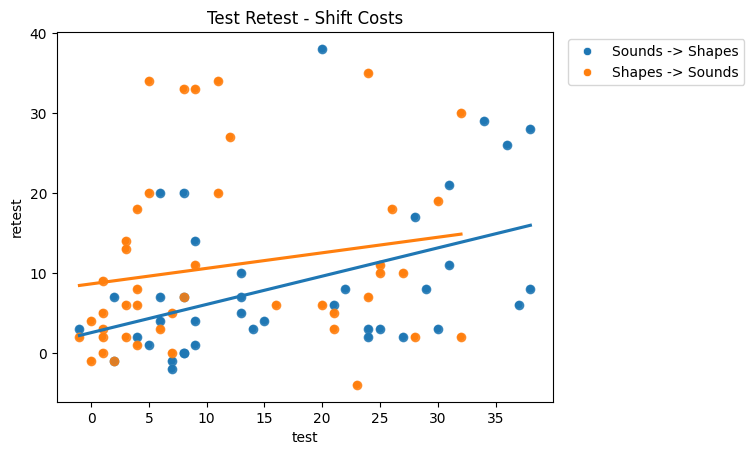

In [8]:
# split task versions for regplot
test_retest_summary['version'] = test_retest_summary['version'].replace({0:'Sounds -> Shapes',1: 'Shapes -> Sounds'})
tmp_0 = test_retest_summary[test_retest_summary['version'] == 'Sounds -> Shapes']
tmp_1 = test_retest_summary[test_retest_summary['version'] == 'Shapes -> Sounds']

sns.scatterplot(x='test',y='retest',data=test_retest_summary,hue='version')
plt.title('Test Retest - Shift Costs')
sns.regplot(x='test',y='retest',data=tmp_0,ci=False)
sns.regplot(x='test',y='retest',data=tmp_1,ci=False)
plt.legend(loc='upper right', bbox_to_anchor=(1.4,1))
plt.savefig('plots/old_scatter.svg', format='svg')

In [15]:
tmp_0.index

Index(['560aef7d01c38a00127693d3', '56d1f7f67bbc32000589a588',
       '571bdaa76b0894001362f780', '582f8bbd4cadc80001b0fbd3',
       '5aae93f5fb22320001baaaac', '5b2240df023fe3000150533f',
       '5b4a3ab1bc06c90001f902f4', '5cf6e4aae289a80019b6e032',
       '5da486f989f3800015f5a4d3', '5e7dfc715acd1402882e93eb',
       '5f3a7e7b3a55e009ff81175e', '5fa82323c6e9e462824a3998',
       '60d075b6af3d46debaf3cfd8', '613bae70cab01ced932e5e9f',
       '61618cbffc5ccf427b976ec7', '6228bb4a2d9521a055debb4a',
       '62d793b216e1b007c88f156f', '62e3f7b224ec70641fd86b7b',
       '637fcee60a8378c1c3a65898', '63d1125c54e8148f4cd30a65',
       '63e51ccb431bed8154fc6aae', '64137cf15dfe79e9ff198054',
       '644805884189b40893adfa53', '644833e25c2d5867d6db1c5a',
       '644f8c80b71e16db44251de7', '654a44f0addb5f41f1705b75',
       '66229d058f6be22dcb26239e', '663ccb353b6d9966bcce762a',
       '66bbafb05de7e549455aa4ff', '6752eedfdeef0e65b35d9567',
       '67673a7ecec3cd778dfbd91f', '6775c5ef1f8667141b3

In [108]:
np.mean(wide['retest'])

np.float64(8.416666666666666)

LIFETP112


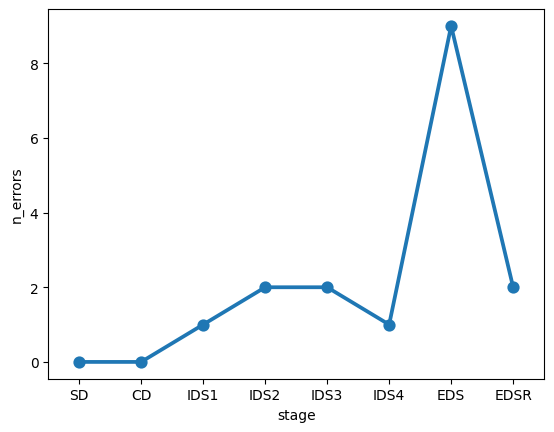

LIFETP117


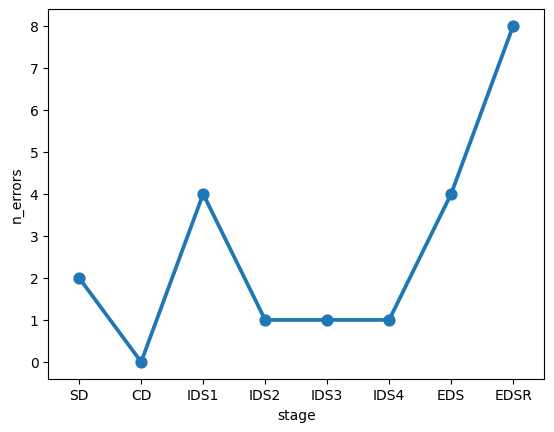

LIFETP119


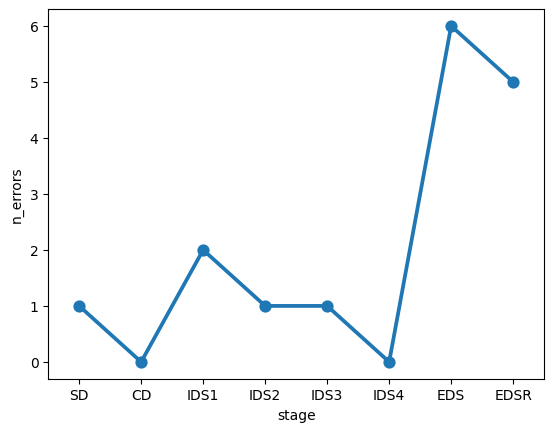

LIFETP120


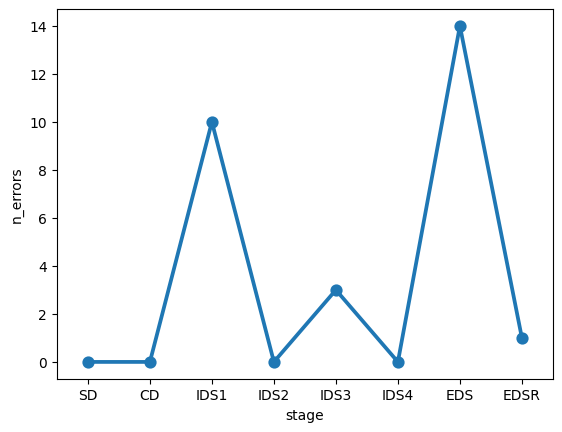

LIFETP121


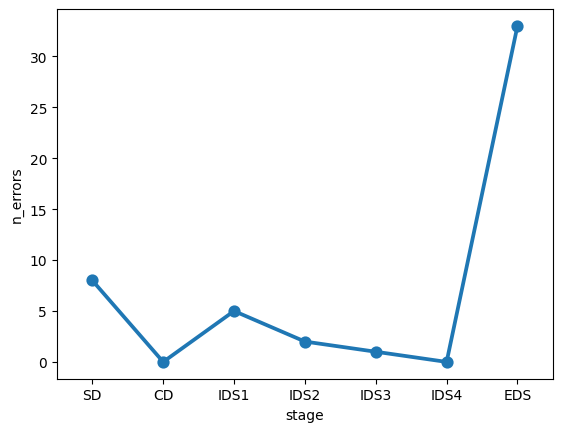

LIFETP122


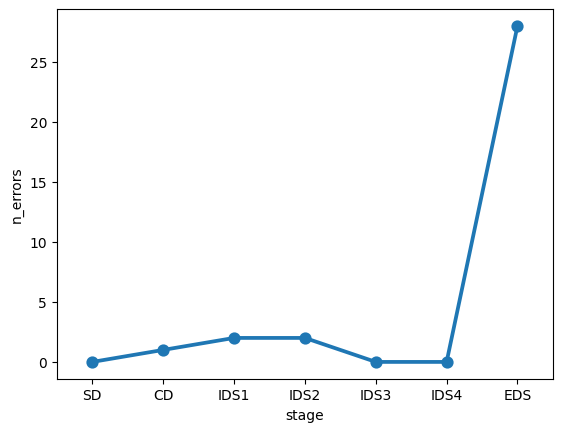

LIFETP123


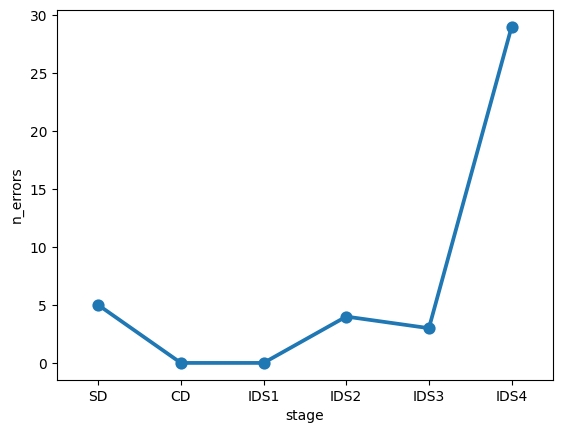

LIFETP124


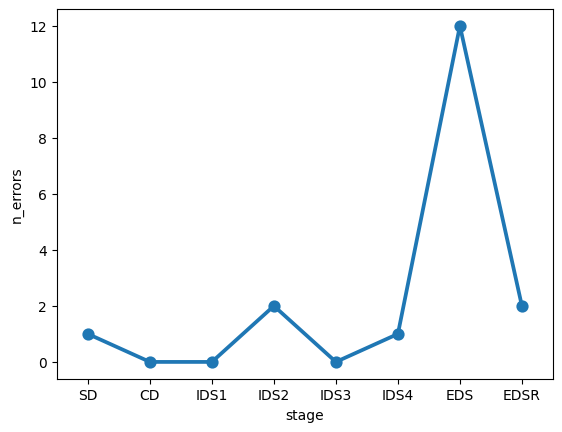

LIFETP125


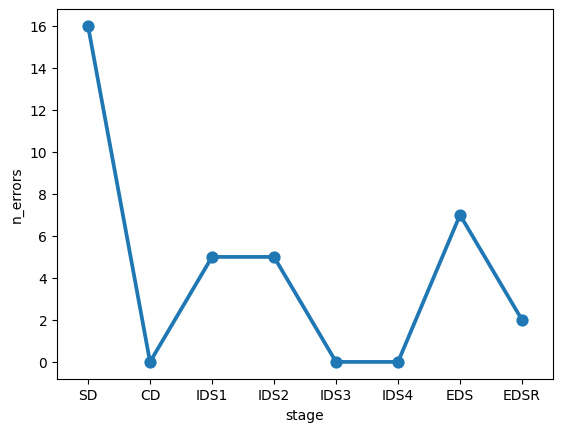

LIFETP126


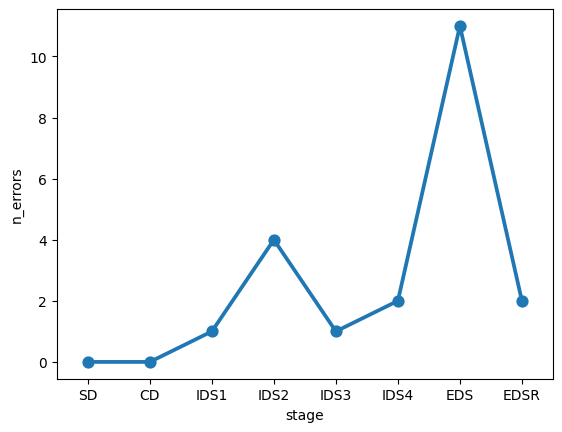

In [ ]:
for id in errors_df['Participant Public ID'].unique():
    tmp = errors_df[errors_df['Participant Public ID'] == id]
    sns.pointplot(data=tmp, x='stage', y='n_errors')
    print(id)
    plt.show()
    

-0.337984303334139
0.018798356301511106


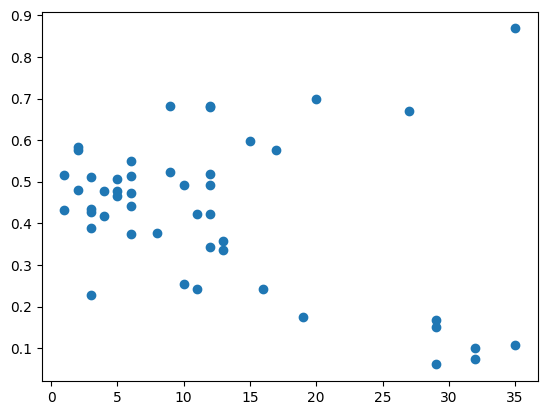

In [45]:
# correlations
x = shifts_df[shifts_df['task'] == '3 Arm']
tmp = pd.merge(x,params,on='Participant Public ID')

# get correlations 
corr, p_value = pearsonr(tmp['costs'],tmp['eps'])
print(corr)
print(p_value)
plt.scatter(tmp['costs'],tmp['eps'])

In [ ]:
# shigt cost correlations across time points

# get data
x = shifts_df[shifts_df['task'] == 'Visual 2']
y = shifts_df[shifts_df['task'] == 'Auditory 1']
x = pd.merge(x,y,on='Participant Public ID')

# get correlations 
corr, p_value = pearsonr(x['costs_x'],x['costs_y'])
print(corr)
print(p_value)

-0.04254649138256521
0.5739195252067499


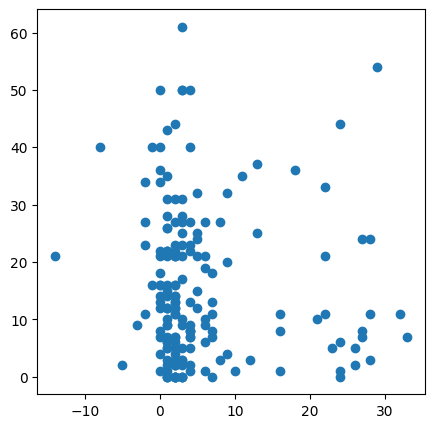

In [51]:
# correlations between behaviour and qaires
x = shifts_df[shifts_df['task'].isin(['Auditory 2','Visual 2'])]
y = oci_r
x = pd.merge(x,y,on='Participant Public ID')

# get correlations 
corr, p_value = pearsonr(x['costs'],x['Response'])
print(corr)
print(p_value)
plt.figure(figsize=(5,5))
plt.scatter(x['costs'],x['Response'])

In [ ]:
# correlations between parameters and qaires

# read data
path= 'data/modelling/fits/safrl/human/apre_2.pkl'
with open(path, 'rb') as f:
    apre_1 = pickle.load(f)
eps_1 = apre_1['m'][:,3]    

# bind with ids
subjs = auditory_pre_1['Participant Public ID'].unique()
subjs = subjs[~pd.isnull(subjs)]
eps_1 = pd.DataFrame({'param': eps_1, 'id': subjs})

# read data
path= 'data/modelling/fits/safrl/human/apre_pilot2.pkl'
with open(path, 'rb') as f:
    apre_2 = pickle.load(f)
eps_2 = apre_2['m'][:,3]   

# bind with ids
subjs = auditory_pre_2['Participant Public ID'].unique()
subjs = subjs[~pd.isnull(subjs)]
eps_2 = pd.DataFrame({'param': eps_2, 'id': subjs})
